# 02 · Classical machine learning (Unit 2)

* Full scikit-learn `Pipeline` with a `ColumnTransformer` (imputer + scaler for numbers, one-hot for categories)
* Decision Tree, Extra Trees, Gradient Boosting and XGBoost, the boosters with **early stopping on the 2023 validation year**
* Missing data: imputation strategies vs XGBoost's native missing-value handling
* Feature selection: stability selection, Boruta, forward and backward selection
* Hyperparameter tuning: manual baseline vs grid vs random vs Bayesian (Optuna), same CV, compared on score and time

Every number is compared with two naive baselines. Model choices are made on **validation (2023)**;
the test years (2024+) are only scored once at the end.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import xgboost as xgb
from boruta import BorutaPy
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import loguniform, randint, uniform

from src import features as F
from src.evaluate import baselines, clf_metrics, reg_metrics, youden_threshold
from src.train import DEFAULT_CLF, DEFAULT_REG, fit_xgb

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")
FIG = Path("docs/figures"); OUT = Path("frontend/public/insights")
SEED = 42

df = F.load()
tr, va, te = F.splits(df)
Xtr, ytr = F.xy(tr); Xva, yva = F.xy(va); Xte, yte = F.xy(te)
ctr, cva, cte = (d["listed_positive"].astype(int) for d in (tr, va, te))
tscv = TimeSeriesSplit(n_splits=5)   # rows are sorted by issue close date
print(f"train {len(tr)} | val {len(va)} | test {len(te)} | features {Xtr.shape[1]}")

train 256 | val 58 | test 290 | features 35


## 0. Baselines (fit on train only)
* **Regression:** always predict the median training gain.
* **Classification:** "positive if total subscription > t", with t chosen on train by F1.

In [2]:
base = baselines(tr, {"val": va, "test": te})
base

,split,model,MAE,RMSE,R2,ROC_AUC,F1,Precision,Recall,Accuracy,Balanced_Accuracy
0,val,Baseline: median gain (5.0%) / total_x > 1.99,25.664097,38.493483,-0.490055,0.847195,0.882353,0.818182,0.957447,0.793103,0.524178
1,test,Baseline: median gain (5.0%) / total_x > 1.99,18.895218,30.853637,-0.171839,0.834644,0.839560,0.760956,0.936275,0.748276,0.619300


Two simple yardsticks. The median baseline misses by 25.7 points on 2023, a hot year where the training median (5.0%) is far too low. The subscription rule ("up if total subscription > 2.0x") already has ROC-AUC 0.85 on 2023: any model has to beat this.

## 1. A full scikit-learn pipeline
`ColumnTransformer` → median imputation (+ missing indicators) and standard scaling on the numeric
columns, one-hot encoding on `exchange` and `sector`. Trees don't need scaling, but the same
pipeline is reused for the linear and neural models, so it is applied consistently.

In [3]:
pre = F.sklearn_preprocessor()
pre.fit(Xtr)
print("columns after preprocessing:", len(pre.get_feature_names_out()))
pre

columns after preprocessing: 67


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['log_qib_x', 'log_nii_x', 'log_bnii_x',
                                  'log_snii_x', 'log_retail_x',
                                  'log_employee_x', 'log_total_x',
                                  'log_issue_size_cr', 'log_anchor_portion_cr',
                                  'log_price_band_upper', 'log_lot_size',
                                  'log_min_investment', 'lo...
                                  'fresh_issue_pct', 'anchor_pct_of_issue',
                                  'retail_reserved_pct', 'listing_month',
                                  'issue_days_open', 'nifty_ret_7d',
                                  'nifty_ret_30d', 'vix_close', 'ipo_heat_30d',
                                  'prev_gain_mean_90d', 'prev_count_90d',
                                  'revenue_growth_pct', 'pat_margin_pct',
                                  'roe_pct', 'debt_equity', ...]),
                                ('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['exchange', 'sector'])],
                  verbose_feature_names_out=False)

## 2. Four tree models (regression target: listing_gain_pct)
Gradient Boosting and XGBoost use **early stopping on the validation year**, not a random
hold-out inside the training data, so the number of trees is chosen by "how well does it do on the
next year", which is the real use case.

In [4]:
results, timings = [], {}

def record(name, pred_va, pred_te=None):
    row = {"model": name, **{f"val_{k}": v for k, v in reg_metrics(yva, pred_va).items()}}
    results.append(row)
    return row

record("Baseline: median", np.full(len(va), tr.listing_gain_pct.median()))

t0 = time.time()
dt = Pipeline([("pre", F.sklearn_preprocessor()), ("m", DecisionTreeRegressor(max_depth=4, min_samples_leaf=10, random_state=SEED))]).fit(Xtr, ytr)
timings["Decision Tree"] = time.time() - t0
record("Decision Tree (depth 4)", dt.predict(Xva))

t0 = time.time()
et = Pipeline([("pre", F.sklearn_preprocessor()), ("m", ExtraTreesRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=2))]).fit(Xtr, ytr)
timings["Extra Trees"] = time.time() - t0
record("Extra Trees", et.predict(Xva))

# Gradient Boosting: fit many stages, then pick the stage with the best validation MAE
t0 = time.time()
gb = Pipeline([("pre", F.sklearn_preprocessor()), ("m", GradientBoostingRegressor(loss="huber", n_estimators=1500, learning_rate=0.02, max_depth=3, subsample=0.8, random_state=SEED))]).fit(Xtr, ytr)
Zva = gb[:-1].transform(Xva)
val_curve = [np.mean(np.abs(yva - p)) for p in gb[-1].staged_predict(Zva)]
best_gb = int(np.argmin(val_curve)) + 1
gb.set_params(m__n_estimators=best_gb).fit(Xtr, ytr)
timings["Gradient Boosting"] = time.time() - t0
record(f"Gradient Boosting (early-stopped at {best_gb} trees)", gb.predict(Xva))

t0 = time.time()
xg = fit_xgb(DEFAULT_REG, Xtr, ytr, Xva, yva, kind="reg")
timings["XGBoost"] = time.time() - t0
record(f"XGBoost (early-stopped at {xg.best_iteration + 1} trees)", xg.predict(Xva))

reg_table = pd.DataFrame(results).round(3)
reg_table

,model,val_MAE,val_RMSE,val_R2
0,Baseline: median,25.664,38.493,-0.490
1,Decision Tree (depth 4),21.412,30.997,0.034
2,Extra Trees,14.834,22.813,0.477
3,Gradient Boosting (early-stopped at 128 trees),14.518,21.618,0.530
4,XGBoost (early-stopped at 164 trees),14.812,22.662,0.484


**Regression on 2023:** every ensemble beats the median baseline by about 11 points (MAE about 14.5 to 14.8 vs 25.7), and the three ensembles are within 0.3 points of each other, which is noise on 58 IPOs. A single depth-4 tree (21.4) is far worse: averaging many trees is what makes the difference. Early stopping on 2023 picked 128 trees for Gradient Boosting and 164 for XGBoost.

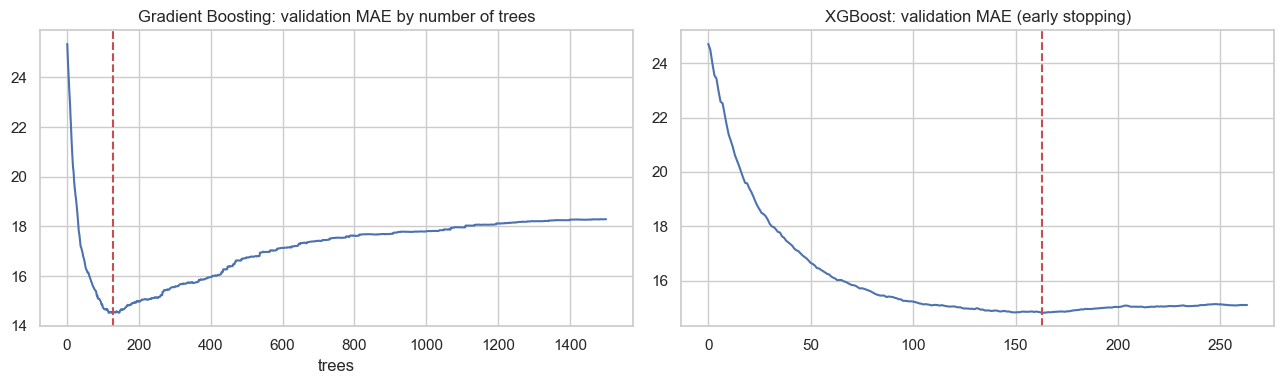

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(range(1, len(val_curve) + 1), val_curve); ax[0].axvline(best_gb, ls="--", c="r")
ax[0].set_title("Gradient Boosting: validation MAE by number of trees"); ax[0].set_xlabel("trees")
ev = xg.evals_result()["validation_0"]["mae"]
ax[1].plot(ev); ax[1].axvline(xg.best_iteration, ls="--", c="r"); ax[1].set_title("XGBoost: validation MAE (early stopping)")
plt.tight_layout(); plt.savefig(FIG / "ml_early_stopping.png", dpi=120); plt.show()

### Same four models as classifiers (target: listed_positive)

In [6]:
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

clf_rows = [{"model": "Baseline: total_x threshold", **{f"val_{k}": v for k, v in base[base.split == "val"].iloc[0][["ROC_AUC", "F1", "Precision", "Recall", "Accuracy"]].items()}}]
for name, est in [
    ("Decision Tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEED)),
    ("Extra Trees", ExtraTreesClassifier(n_estimators=500, min_samples_leaf=5, max_features=0.5, random_state=SEED, n_jobs=2)),
    ("Gradient Boosting", GradientBoostingClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=SEED)),
]:
    p = Pipeline([("pre", F.sklearn_preprocessor()), ("m", est)]).fit(Xtr, ctr).predict_proba(Xva)[:, 1]
    clf_rows.append({"model": name, **{f"val_{k}": v for k, v in clf_metrics(cva, p).items()}})
xc = fit_xgb(DEFAULT_CLF, Xtr, ctr, Xva, cva, kind="clf")
clf_rows.append({"model": f"XGBoost (early-stopped at {xc.best_iteration + 1})", **{f"val_{k}": v for k, v in clf_metrics(cva, xc.predict_proba(Xva)[:, 1]).items()}})
clf_table = pd.DataFrame(clf_rows).round(3)
clf_table

,model,val_ROC_AUC,val_F1,val_Precision,val_Recall,val_Accuracy,val_Balanced_Accuracy
0,Baseline: total_x threshold,0.847,0.882,0.818,0.957,0.793,NaN
1,Decision Tree,0.777,0.875,0.857,0.894,0.793,0.629
2,Extra Trees,0.836,0.902,0.836,0.979,0.828,0.580
3,Gradient Boosting,0.847,0.882,0.891,0.872,0.810,0.709
4,XGBoost (early-stopped at 19),0.863,0.895,0.810,1.000,0.810,0.500


**Up/down on 2023:** only XGBoost edges the subscription rule on ROC-AUC (0.86 vs 0.85). Its recall of 1.0 and balanced accuracy of 0.50 show the catch: at a 0.5 cut-off it calls every IPO "up", because about 80% of 2023 IPOs did list up and its scores never drop below 0.5. Section 6 fixes this by choosing the cut-off on 2023.

## 3. Missing data: imputation vs XGBoost's native handling
XGBoost learns a default direction for missing values at every split. The alternative is to
fill them first. Same XGBoost settings, same early stopping, only the treatment of NaN changes.

In [7]:
num = F.numeric_names()
Xtr_n = Xtr.assign(exchange=Xtr.exchange.cat.codes, sector=Xtr.sector.cat.codes)
Xva_n = Xva.assign(exchange=Xva.exchange.cat.codes, sector=Xva.sector.cat.codes)
Xte_n = Xte.assign(exchange=Xte.exchange.cat.codes, sector=Xte.sector.cat.codes)

imputers = {
    "XGBoost native (no imputation)": None,
    "Mean": SimpleImputer(strategy="mean"),
    "Median": SimpleImputer(strategy="median"),
    "Median + missing indicators": SimpleImputer(strategy="median", add_indicator=True),
    "KNN (k=10, scaled)": Pipeline([("s", StandardScaler()), ("i", KNNImputer(n_neighbors=10))]),
    "Iterative (BayesianRidge)": IterativeImputer(max_iter=15, random_state=SEED),
}
imp_rows = []
for name, imp in imputers.items():
    if imp is None:
        A, B = Xtr_n.values, Xva_n.values
    else:
        imp = clone(imp).fit(Xtr_n)
        A, B = imp.transform(Xtr_n), imp.transform(Xva_n)
    m = xgb.XGBRegressor(n_estimators=2000, early_stopping_rounds=100, eval_metric="mae", random_state=SEED, **DEFAULT_REG)
    m.fit(A, ytr, eval_set=[(B, yva)], verbose=False)
    imp_rows.append({"strategy": name, "val_MAE": reg_metrics(yva, m.predict(B))["MAE"], "val_R2": reg_metrics(yva, m.predict(B))["R2"], "trees": m.best_iteration + 1})
imp_table = pd.DataFrame(imp_rows).round(3).sort_values("val_MAE")
imp_table

,strategy,val_MAE,val_R2,trees
0,XGBoost native (no imputation),14.589,0.501,163
3,Median + missing indicators,14.745,0.502,193
5,Iterative (BayesianRidge),14.860,0.483,163
2,Median,14.877,0.484,164
4,"KNN (k=10, scaled)",14.890,0.478,151
1,Mean,14.933,0.483,211


**Imputation:** XGBoost's native handling is best (14.59), but all six strategies are within 0.35 points, so the honest conclusion is "it does not matter here". Native handling is kept: it is simplest, and the missingness is informative (the bNII/sNII split only exists from 2022).

## 4. Feature selection: which features survive across methods?
Four very different methods on the training years only:
1. **Stability selection**: Lasso on 200 random half-samples over a grid of penalties; keep features selected in ≥ 60 % of fits at some penalty.
2. **Boruta**: keep features whose Random Forest importance beats their own shuffled "shadow" copies.
3. **Forward selection** and 4. **backward elimination** (`SequentialFeatureSelector`) with a small XGBoost, scored by MAE under `TimeSeriesSplit`.

`exchange` and `sector` are integer-coded here so all methods see the same columns.

In [8]:
cols = list(Xtr_n.columns)
med_imp = SimpleImputer(strategy="median").fit(Xtr_n)
Atr = pd.DataFrame(med_imp.transform(Xtr_n), columns=cols)

# 1) stability selection
Zs = StandardScaler().fit_transform(Atr)
rng = np.random.default_rng(SEED)
alphas = [0.5, 1.0, 2.0, 4.0]
freq = np.zeros((len(alphas), len(cols)))
for _ in range(200):
    idx = rng.choice(len(Zs), size=len(Zs) // 2, replace=False)
    for a_i, a in enumerate(alphas):
        coef = Lasso(alpha=a, max_iter=5000).fit(Zs[idx], ytr.values[idx]).coef_
        freq[a_i] += coef != 0
stab_prob = pd.Series((freq / 200).max(axis=0), index=cols)
sel_stability = set(stab_prob[stab_prob >= 0.6].index)

# 2) Boruta
t0 = time.time()
bor = BorutaPy(RandomForestRegressor(n_estimators=300, max_depth=5, random_state=SEED, n_jobs=2), n_estimators="auto", max_iter=100, random_state=SEED)
bor.fit(Atr.values, ytr.values)
sel_boruta = {c for c, s in zip(cols, bor.support_) if s}
sel_boruta_tentative = {c for c, s in zip(cols, bor.support_weak_) if s}

# 3/4) forward + backward selection with a small XGBoost
small = xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=1)
sfs_f = SequentialFeatureSelector(small, n_features_to_select=12, direction="forward", scoring="neg_mean_absolute_error", cv=TimeSeriesSplit(4), n_jobs=2).fit(Xtr_n, ytr)
sel_forward = set(np.array(cols)[sfs_f.get_support()])
sfs_b = SequentialFeatureSelector(small, n_features_to_select=12, direction="backward", scoring="neg_mean_absolute_error", cv=TimeSeriesSplit(4), n_jobs=2).fit(Xtr_n, ytr)
sel_backward = set(np.array(cols)[sfs_b.get_support()])

survival = pd.DataFrame({
    "stability (p≥0.6)": [c in sel_stability for c in cols],
    "Boruta": [c in sel_boruta for c in cols],
    "forward SFS": [c in sel_forward for c in cols],
    "backward SFS": [c in sel_backward for c in cols],
}, index=cols)
survival["votes"] = survival.sum(axis=1)
survival["stability_prob"] = stab_prob.round(2)
survival = survival.sort_values(["votes", "stability_prob"], ascending=False)
print("Boruta tentative:", sorted(sel_boruta_tentative))
survival.head(20)

Boruta tentative: ['log_anchor_portion_cr']


,stability (p≥0.6),Boruta,forward SFS,backward SFS,votes,stability_prob
log_total_x,True,True,True,False,3,1.00
log_retail_x,True,True,False,True,3,0.98
log_snii_x,True,False,True,True,3,0.92
ipo_heat_30d,True,False,True,True,3,0.82
roe_pct,True,False,True,True,3,0.80
log_qib_x,True,True,False,True,3,0.64
prev_gain_mean_90d,True,False,False,True,2,0.90
issue_days_open,True,False,True,False,2,0.79
log_revenue_cr,True,False,False,True,2,0.78
sector,True,False,True,False,2,0.78


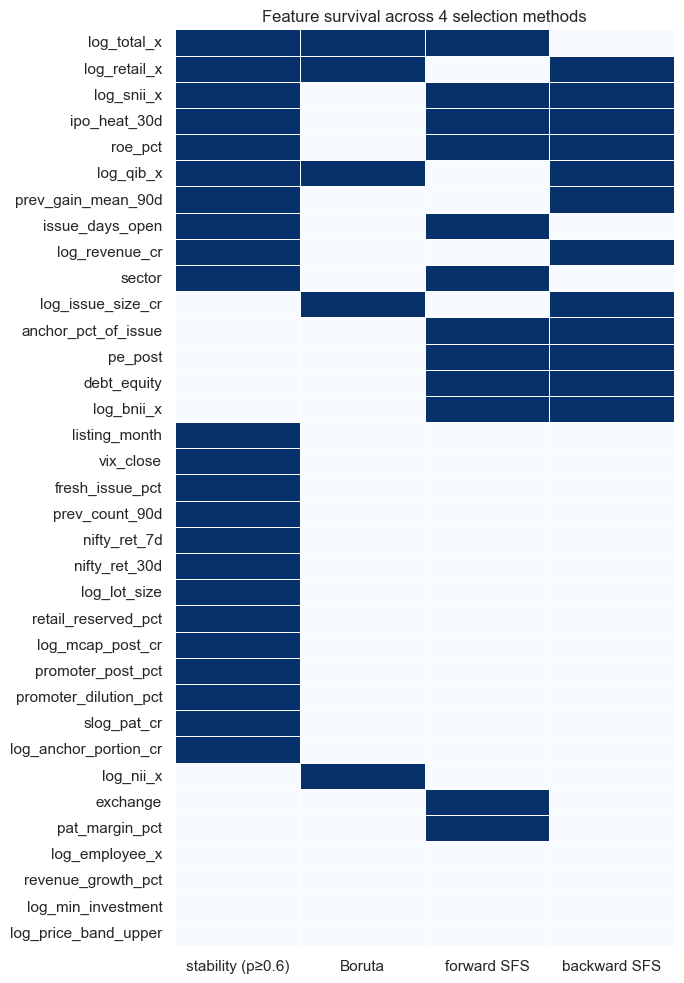

In [9]:
plt.figure(figsize=(7, 10))
sns.heatmap(survival.iloc[:, :4].astype(int), cmap="Blues", cbar=False, linewidths=0.5)
plt.title("Feature survival across 4 selection methods"); plt.tight_layout(); plt.savefig(FIG / "ml_feature_survival.png", dpi=120); plt.show()

Does using only the consensus features help on validation?

In [10]:
fs_rows = []
for name, keep in {
    "all features": cols,
    "≥2 votes": survival[survival.votes >= 2].index.tolist(),
    "≥3 votes": survival[survival.votes >= 3].index.tolist(),
    "forward SFS 12": sorted(sel_forward),
}.items():
    if not keep:
        continue
    m = xgb.XGBRegressor(n_estimators=2000, early_stopping_rounds=100, eval_metric="mae", random_state=SEED, **DEFAULT_REG)
    m.fit(Xtr_n[keep], ytr, eval_set=[(Xva_n[keep], yva)], verbose=False)
    fs_rows.append({"feature set": name, "n_features": len(keep), **{f"val_{k}": v for k, v in reg_metrics(yva, m.predict(Xva_n[keep])).items()}})
fs_table = pd.DataFrame(fs_rows).round(3)
fs_table

,feature set,n_features,val_MAE,val_RMSE,val_R2
0,all features,35,14.589,22.284,0.501
1,≥2 votes,15,14.676,22.184,0.505
2,≥3 votes,6,13.841,21.701,0.526
3,forward SFS 12,12,15.133,23.499,0.445


**Feature selection:** total, retail, sNII and QIB subscription, IPO-market heat and ROE survive at least 3 of 4 methods. The 6-feature model is best on 2023 (13.8 vs 14.6 with all 35), but the production model keeps every feature: trees down-weight weak features on their own, a 0.75-point gain on one 58-IPO year is within noise, and choosing the feature set by its 2023 score would use up the validation year. The app's SHAP explanation also needs every input.

## 5. Hyperparameter tuning: manual vs grid vs random vs Bayesian (Optuna)
All four use the **same objective**: mean MAE over a 5-fold `TimeSeriesSplit` on the training years
(each fold trains on the past, validates on the following block). The validation year is then used to
check whether the CV winner also wins one year ahead.

In [11]:
def cv_mae(params):
    m = xgb.XGBRegressor(enable_categorical=True, tree_method="hist", random_state=SEED, n_jobs=2, **params)
    return -cross_val_score(m, Xtr, ytr, cv=tscv, scoring="neg_mean_absolute_error").mean()

def val_mae(params):
    m = xgb.XGBRegressor(enable_categorical=True, tree_method="hist", random_state=SEED, n_jobs=2, **params).fit(Xtr, ytr)
    return reg_metrics(yva, m.predict(Xva))["MAE"]

base_est = xgb.XGBRegressor(enable_categorical=True, tree_method="hist", random_state=SEED, n_jobs=2, objective="reg:pseudohubererror", huber_slope=10.0)
tune = []

# manual: the hand-picked defaults
manual = {**DEFAULT_REG, "n_estimators": 400}
t0 = time.time(); s = cv_mae(manual); dt_ = time.time() - t0
tune.append({"method": "Manual (hand-picked)", "fits": 5, "cv_MAE": s, "val_MAE": val_mae(manual), "seconds": dt_, "params": manual})

# grid search
grid = {"max_depth": [2, 3, 4], "learning_rate": [0.02, 0.05, 0.1], "n_estimators": [200, 500], "min_child_weight": [1, 5, 10], "subsample": [0.8]}
t0 = time.time()
gs = GridSearchCV(base_est, grid, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=2).fit(Xtr, ytr)
p = {**base_est.get_params(), **gs.best_params_}; p = {k: p[k] for k in list(grid) + ["objective", "huber_slope"]}
tune.append({"method": "Grid search", "fits": len(gs.cv_results_["params"]) * 5, "cv_MAE": -gs.best_score_, "val_MAE": val_mae(p), "seconds": time.time() - t0, "params": p})

# random search, same number of candidates as the grid
space = {"max_depth": randint(2, 7), "learning_rate": loguniform(0.01, 0.3), "n_estimators": randint(100, 1200),
         "min_child_weight": randint(1, 20), "subsample": uniform(0.5, 0.5), "colsample_bytree": uniform(0.4, 0.6),
         "reg_lambda": loguniform(0.1, 50), "reg_alpha": loguniform(1e-3, 10)}
t0 = time.time()
rs = RandomizedSearchCV(base_est, space, n_iter=len(gs.cv_results_["params"]), cv=tscv, scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=2).fit(Xtr, ytr)
p = {**rs.best_params_, "objective": "reg:pseudohubererror", "huber_slope": 10.0}
tune.append({"method": "Random search", "fits": len(rs.cv_results_["params"]) * 5, "cv_MAE": -rs.best_score_, "val_MAE": val_mae(p), "seconds": time.time() - t0, "params": p})

# Bayesian optimisation with Optuna (TPE), same budget
def objective(trial):
    params = {
        "objective": "reg:pseudohubererror",
        "huber_slope": trial.suggest_float("huber_slope", 2.0, 30.0, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1200),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 50, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    }
    return cv_mae(params)

t0 = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=len(gs.cv_results_["params"]))
p = {"objective": "reg:pseudohubererror", **study.best_params}
tune.append({"method": "Bayesian (Optuna TPE)", "fits": len(study.trials) * 5, "cv_MAE": study.best_value, "val_MAE": val_mae(p), "seconds": time.time() - t0, "params": p})

tune_table = pd.DataFrame(tune)
tune_table[["method", "fits", "cv_MAE", "val_MAE", "seconds"]].round(3)

,method,fits,cv_MAE,val_MAE,seconds
0,Manual (hand-picked),5,15.856,15.212,2.033
1,Grid search,270,14.978,15.922,58.962
2,Random search,270,15.135,16.445,160.559
3,Bayesian (Optuna TPE),270,14.748,15.830,299.393


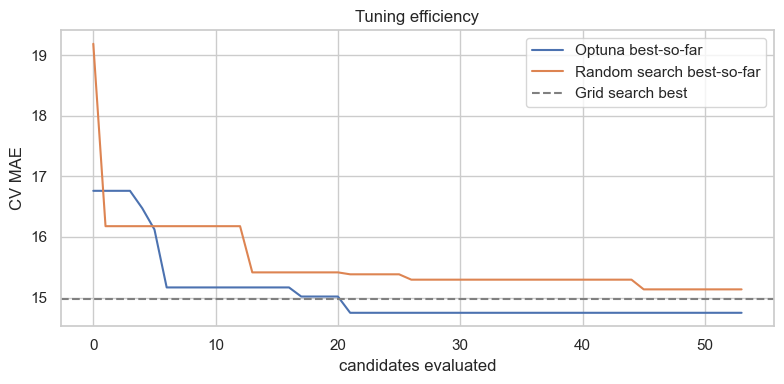

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
best_so_far = np.minimum.accumulate([t.value for t in study.trials])
ax.plot(best_so_far, label="Optuna best-so-far")
rs_curve = np.minimum.accumulate(-rs.cv_results_["mean_test_score"])
ax.plot(rs_curve, label="Random search best-so-far")
ax.axhline(-gs.best_score_, ls="--", c="gray", label="Grid search best")
ax.set_xlabel("candidates evaluated"); ax.set_ylabel("CV MAE"); ax.legend(); ax.set_title("Tuning efficiency")
plt.tight_layout(); plt.savefig(FIG / "ml_tuning.png", dpi=120); plt.show()

**Tuning:** with the same 270-fit budget, Optuna found the best CV score (14.75), then grid (14.98) and random search (15.14), all better than the 5 hand-picked settings (15.86). But on the **next year** the hand-picked settings win (15.2 vs 15.8 to 16.4): the searches tuned themselves to the 2012-2022 regime. So the production parameters are picked by 2023 MAE, which selects the manual settings (depth 3, learning rate 0.03, pseudo-Huber loss).

### Tune the classifier with Optuna too (objective: CV ROC-AUC)

In [13]:
def objective_clf(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 50, log=True),
    }
    m = xgb.XGBClassifier(enable_categorical=True, tree_method="hist", random_state=SEED, n_jobs=2, **params)
    return cross_val_score(m, Xtr, ctr, cv=tscv, scoring="roc_auc").mean()

study_c = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_c.optimize(objective_clf, n_trials=60)
print("best CV ROC-AUC", round(study_c.best_value, 3), study_c.best_params)

best CV ROC-AUC 0.81 {'max_depth': 3, 'learning_rate': 0.011120233238466667, 'n_estimators': 645, 'min_child_weight': 2, 'subsample': 0.5743169051075395, 'colsample_bytree': 0.5842383380701412, 'reg_lambda': 30.46881511232989}


### Pick the production hyperparameters
Choose the regression search whose winner has the best **validation** MAE (one year ahead), not just
the best CV score, since CV on 2012–2022 can reward settings that fit one regime. `n_estimators` is
dropped: the training script re-picks the number of trees by early stopping on 2023.

In [14]:
winner = tune_table.sort_values("val_MAE").iloc[0]
reg_params = {k: v for k, v in winner["params"].items() if k != "n_estimators"}
clf_params = {k: v for k, v in study_c.best_params.items() if k != "n_estimators"}
Path("models").mkdir(exist_ok=True)
Path("models/best_params.json").write_text(json.dumps({"reg": reg_params, "clf": clf_params, "reg_source": winner["method"]}, indent=2, default=float))
print("regression winner:", winner["method"]); print(json.dumps(reg_params, indent=1, default=float))

regression winner: Manual (hand-picked)
{
 "objective": "reg:pseudohubererror",
 "huber_slope": 10.0,
 "learning_rate": 0.03,
 "max_depth": 3,
 "min_child_weight": 5,
 "subsample": 0.8,
 "colsample_bytree": 0.7,
 "reg_lambda": 5.0,
 "reg_alpha": 0.0
}


## 6. Classical models on the test years (scored once)
Refit on train + validation (2012–2023) with the number of trees from early stopping, then score 2024+.

In [15]:
from src.train import _params
rp, cp = _params()
trva = pd.concat([tr, va]); Xtv, ytv = F.xy(trva)
reg_es = fit_xgb(rp, Xtr, ytr, Xva, yva, kind="reg"); clf_es = fit_xgb(cp, Xtr, ctr, Xva, cva, kind="clf")
reg_final = fit_xgb(rp, Xtv, ytv, n_estimators=reg_es.best_iteration + 1, kind="reg")
clf_final = fit_xgb(cp, Xtv, trva.listed_positive.astype(int), n_estimators=clf_es.best_iteration + 1, kind="clf")
# the tuned classifier's scores sit in a narrow band above 0.5, so 0.5 would call every IPO "up";
# the cut-off is chosen on the 2023 validation year (Youden's J), as in src/train.py
cut = youden_threshold(cva, clf_es.predict_proba(Xva)[:, 1])
print(f"validation-chosen cut-off: {cut:.3f}")

gbf = Pipeline([("pre", F.sklearn_preprocessor()), ("m", GradientBoostingRegressor(loss="huber", n_estimators=best_gb, learning_rate=0.02, max_depth=3, subsample=0.8, random_state=SEED))]).fit(Xtv, ytv)
etf = clone(et).fit(Xtv, ytv)
test_rows = [
    {"model": "Baseline (median / total_x rule)", **{k: base[base.split == "test"].iloc[0][k] for k in ["MAE", "RMSE", "R2", "ROC_AUC", "F1", "Balanced_Accuracy"]}},
    {"model": "Extra Trees", **reg_metrics(yte, etf.predict(Xte))},
    {"model": "Gradient Boosting", **reg_metrics(yte, gbf.predict(Xte))},
    {"model": "XGBoost (tuned)", **reg_metrics(yte, reg_final.predict(Xte)), **{k: v for k, v in clf_metrics(cte, clf_final.predict_proba(Xte)[:, 1], cut).items() if k in ("ROC_AUC", "F1", "Balanced_Accuracy")}},
]
test_table = pd.DataFrame(test_rows).round(3)
test_table

validation-chosen cut-off: 0.713


,model,MAE,RMSE,R2,ROC_AUC,F1,Balanced_Accuracy
0,Baseline (median / total_x rule),18.895,30.854,-0.172,0.835,0.840,0.619
1,Extra Trees,20.688,28.297,0.014,NaN,NaN,NaN
2,Gradient Boosting,18.679,25.510,0.199,NaN,NaN,NaN
3,XGBoost (tuned),20.099,27.797,0.049,0.823,0.784,0.746


**Test years (2024+), scored once.** On MAE no classical model clearly beats the median baseline (18.9; Gradient Boosting 18.7, XGBoost 20.1, Extra Trees 20.7), but all of them cut RMSE (30.9 down to 25.5-28.3): they get the large listings closer while adding error on ordinary ones. Every model over-predicts the test years because median subscription rose from about 9x to about 34x without listing gains rising to match (notebook 03 quantifies the bias). With the 2023-chosen cut-off of 0.71, XGBoost's balanced accuracy is 0.75 against 0.62 for the subscription rule. Gradient Boosting's better test MAE is not used to switch models: the choice was made on 2023, where XGBoost and Gradient Boosting were tied, and XGBoost gives exact TreeSHAP and native categorical and missing-value handling in the API.

In [16]:
export = {
    "regression_val": reg_table.to_dict(orient="records"),
    "classification_val": clf_table.to_dict(orient="records"),
    "imputation": imp_table.to_dict(orient="records"),
    "feature_survival": survival.reset_index(names="feature").to_dict(orient="records"),
    "feature_sets": fs_table.to_dict(orient="records"),
    "tuning": tune_table[["method", "fits", "cv_MAE", "val_MAE", "seconds"]].to_dict(orient="records"),
    "test_classical": test_table.to_dict(orient="records"),
}
(OUT / "classical.json").write_text(json.dumps(export, default=float))
print("wrote", OUT / "classical.json")

wrote frontend\public\insights\classical.json
